# Pipeline complet — Comparaison de tous les modèles de classification supervisée par validation croisée
**Un seul notebook** : il lance, de bout en bout, la comparaison de toutes les méthodes (de la régression logistique au boosting) en **validation croisée stratifiée à 10 blocs**, puis produit les résultats (tableau, courbes ROC, fichiers `PROB*.csv` pour `03_analyseCS_complet.ipynb`).

**Modèles comparés** (mêmes blocs pour tous, donc résultats comparables) :

| Famille | Colonnes de `PROB` |
|---|---|
| Régression logistique | `log` (sans pénalité), `BIC` / `AIC` (sélection forward) |
| Pénalisation | `ridge`, `lasso`, `elast` (ElasticNet, `l1_ratio=0.5`) |
| Forêt aléatoire | `foret` |
| Boosting | `gbm1`, `gbm2` (gradient boosting, profondeur 1 / 2, early stopping), `cat` (CatBoost, early stopping) |

**Étapes** : 1. configuration → 2. validation croisée de tous les modèles, pour chaque jeu de variables choisi → 3. résultats (indicateurs, AUC, courbes ROC, hyperparamètres retenus par bloc, test final optionnel) → 4. export des fichiers.

**Test final (optionnel)** : avec `TAILLE_TEST_FINAL > 0` (ex. `0.2`), une part des données est mise de côté (de façon stratifiée) **avant** la validation croisée. La validation croisée compare les méthodes sur le reste ; chaque modèle est ensuite réajusté sur tout ce reste et évalué **une seule fois** sur ce test final (section 3.4). Par défaut (`0.0`), il n'y a pas de test final : les probabilités hors échantillon de la validation croisée servent d'évaluation.

**Prérequis** : `01_preparationCS.ipynb` exécuté (il écrit `dfbase.csv`, `dfpoly.csv`, `dfinter.csv`, `dffull.csv`) ; `scikit-learn`, `pandas`, `numpy`, `matplotlib` ; `catboost` (optionnel, sinon `cat` est ignoré) ; `logistic_step_sk.py` dans le même dossier (pour BIC/AIC).

## 1. Configuration

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn.metrics as sklm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings("ignore")

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
    print("catboost non installé (pip install catboost) : la méthode 'cat' sera ignorée")

try:
    import logistic_step_sk as lss
except ImportError:
    lss = None
    print("logistic_step_sk.py introuvable : BIC et AIC seront ignorés")

# ← Paramètres à modifier
JEUX = ["base"]          # jeux de variables à comparer : "base", "poly", "inter", "full" (un ou plusieurs)
NB_BLOCS = 10            # nombre de blocs de la validation croisée
GRAINE_BLOCS = 123       # graine du découpage en blocs (StratifiedKFold)
GRAINE = 42              # graine de tous les modèles et découpages aléatoires (résultats reproductibles)
CALCULER_IC = True       # BIC / AIC forward : rapide avec "base", plus long avec "inter" / "full"
TAILLE_TEST_FINAL = 0.0  # part d'un échantillon de test final, mis de côté AVANT la validation croisée (0 = pas de test final)
GRAINE_TEST = 2024       # graine du tirage (stratifié) de l'échantillon de test final
N_BOOT_IC = 1000         # rééchantillonnages pour l'intervalle de confiance de l'AUC de test
DOSSIER_DONNEES = "./"   # dossier des dfbase.csv, dfpoly.csv... (écrits par 01_preparationCS)
DOSSIER_SORTIE = "./"    # dossier où écrire les fichiers résultats

# Option pour tester le code rapidement : n'utilise qu'une fraction des lignes, tirées au hasard.
# Les résultats n'ont alors aucune valeur ; les fichiers sont écrits dans test_pipeline/ pour ne rien écraser.
MODE_TEST = False        # True pour activer le mode test (CatBoost utilise alors subsample=0.8 : trop peu de lignes pour 0.1)
FRACTION_TEST = 0.10     # part des lignes conservées en mode test
GRAINE_ECHANTILLON = 2025   # graine du tirage des lignes
if MODE_TEST:
    DOSSIER_SORTIE = "test_pipeline/"
    os.makedirs(DOSSIER_SORTIE, exist_ok=True)
    print(f"MODE TEST : {FRACTION_TEST:.0%} des lignes, résultats écrits dans {DOSSIER_SORTIE}")

# jeu -> (fichier de variables, fichier de probabilités lu par 03_analyseCS_complet, fichier du test final : SUFFIXE_PROB = "_cvtest")
FICHIERS = {"base": ("dfbase.csv", "PROB.csv", "PROB_cvtest.csv"), "poly": ("dfpoly.csv", "PROBpoly.csv", "PROBpoly_cvtest.csv"),
            "inter": ("dfinter.csv", "PROBinter.csv", "PROBinter_cvtest.csv"), "full": ("dffull.csv", "PROBfull.csv", "PROBfull_cvtest.csv")}

## 2. Validation croisée de tous les modèles
Les blocs sont **stratifiés** (même proportion de Y=1 dans chaque bloc). Pour chaque bloc, on apprend sur les autres blocs et on prédit la probabilité P(Y=1) du bloc mis de côté : `PROB` contient ainsi, pour chaque observation, une probabilité **hors échantillon** par méthode.

Le paramètre de régularisation C (inverse de λ) est choisi par validation croisée interne sur une grille calée sur l'échelle des données (`grille`).

In [2]:
def grille(X, y, type="lasso", ng=100):
    """Grille de valeurs C (inverse du paramètre de régularisation) adaptée à l'échelle des données,
    à partir de la plus grande valeur utile l0 (au-delà de laquelle le lasso annule tous les coefficients)."""
    Xcr = StandardScaler().fit(X).transform(X)
    l0 = np.abs(Xcr.T.dot(y - y.mean())).max() / X.shape[0]
    llc = np.linspace(0, -4, ng)
    facteur = {"lasso": 1, "ridge": 100, "enet": 2}[type]   # ridge et elastic net ont des échelles décalées
    return 1 / 0.9 / X.shape[0] / (l0 * 10 ** llc * facteur)


def comparer(jeu):
    """Validation croisée stratifiée de toutes les méthodes sur un jeu de variables.
    Renvoie PROB (probabilités hors échantillon), les hyperparamètres retenus par bloc et les temps de calcul."""
    don = pd.read_csv(DOSSIER_DONNEES + FICHIERS[jeu][0])
    if MODE_TEST:
        don = don.sample(frac=FRACTION_TEST, random_state=GRAINE_ECHANTILLON).sort_index()
    X = don.drop(columns=["Y"]).to_numpy()
    Y = don["Y"].to_numpy()
    print(f"\n=== Jeu '{jeu}' : {X.shape[0]} observations x {X.shape[1]} variables ===")

    # Échantillon de test final (optionnel, stratifié) : mis de côté avant la validation croisée
    idx_tous = np.arange(len(Y))
    if TAILLE_TEST_FINAL > 0:
        idx_cv, idx_test = train_test_split(idx_tous, test_size=TAILLE_TEST_FINAL, stratify=Y, random_state=GRAINE_TEST)
        print(f"Test final : {len(idx_test)} observations mises de côté ; validation croisée sur {len(idx_cv)} observations")
    else:
        idx_cv, idx_test = idx_tous, np.array([], dtype=int)

    skf = StratifiedKFold(n_splits=NB_BLOCS, shuffle=True, random_state=GRAINE_BLOCS)
    PROB = pd.DataFrame({"Y": Y})
    params_cv, params_test, temps = {}, {}, {}
    tache = None                                       # bloc en cours, ou "test" pour l'ajustement final

    def enregistrer(nom, val_index, proba, t0, **hyper):
        if nom not in PROB.columns:
            PROB[nom] = 0.0
        PROB.loc[val_index, nom] = proba[:, 1]          # probabilité d'appartenir à la classe Y=1
        if tache == "test":
            params_test.update(hyper)
            return
        temps[nom] = temps.get(nom, 0.0) + time.time() - t0
        for k, v in hyper.items():
            params_cv.setdefault(k, []).append(v)

    # blocs de la validation croisée (indices absolus), puis ajustement final sur toute la partie CV si test final
    taches = [(i, idx_cv[a], idx_cv[v]) for i, (a, v) in enumerate(skf.split(X[idx_cv], Y[idx_cv]))]
    if len(idx_test) > 0:
        taches.append(("test", idx_cv, idx_test))

    for tache, app_index, val_index in taches:
        if tache == "test":
            print("Ajustement final sur toute la partie validation croisée -> prédiction du test final")
        else:
            print(f"Bloc {tache + 1}/{NB_BLOCS}")
        Xapp, Xtest, Yapp = X[app_index], X[val_index], Y[app_index]

        # --- Logistique complète (sans pénalité)
        t0 = time.time()
        log = LogisticRegression(penalty=None, solver="newton-cholesky").fit(Xapp, Yapp)
        enregistrer("log", val_index, log.predict_proba(Xtest), t0)

        # --- Sélection forward par BIC / AIC
        if CALCULER_IC and lss is not None:
            for crit in ("bic", "aic"):
                t0 = time.time()
                choix = lss.LogisticRegressionSelectionFeatureIC(
                    start=[], direction="forward", crit=crit, multi_class="auto").fit(Xapp, Yapp)
                enregistrer(crit.upper(), val_index, choix.predict_proba(Xtest), t0,
                            **{f"nb_var_{crit.upper()}": len(choix.selected_features_)})

        # --- Ridge, lasso, elastic net logistiques (C choisi par CV interne à 10 blocs)
        for nom, type_grille, kwargs in [
            ("ridge", "ridge", dict(penalty="l2", max_iter=1000)),
            ("lasso", "lasso", dict(penalty="l1", solver="saga", max_iter=2000)),
            ("elast", "enet", dict(penalty="elasticnet", solver="saga", l1_ratios=[0.5], max_iter=2000)),
        ]:
            t0 = time.time()
            modele = LogisticRegressionCV(cv=10, Cs=grille(Xapp, Yapp, type_grille), n_jobs=-1,
                                          random_state=GRAINE, **kwargs)
            pipe = Pipeline([("cr", StandardScaler()), ("cv", modele)]).fit(Xapp, Yapp)
            enregistrer(nom, val_index, pipe.predict_proba(Xtest), t0, **{f"C_{nom}": modele.C_[0]})

        # --- Forêt aléatoire
        t0 = time.time()
        foret = RandomForestClassifier(random_state=GRAINE).fit(Xapp, Yapp)
        enregistrer("foret", val_index, foret.predict_proba(Xtest), t0)

        # --- Gradient boosting : early stopping sur 10 % de l'apprentissage (un seul échantillon de validation)
        for nom, profondeur in [("gbm1", 1), ("gbm2", 2)]:
            t0 = time.time()
            gbm = GradientBoostingClassifier(n_estimators=1000, max_depth=profondeur, learning_rate=0.1,
                                             random_state=GRAINE, validation_fraction=0.1,
                                             n_iter_no_change=10).fit(Xapp, Yapp)
            enregistrer(nom, val_index, gbm.predict_proba(Xtest), t0, **{f"nb_iter_{nom}": gbm.n_estimators_})

        # --- CatBoost : early stopping sur UN échantillon de validation (10 % de l'apprentissage), pas par CV
        if CatBoostClassifier is not None:
            t0 = time.time()
            X_tr, X_va, y_tr, y_va = train_test_split(Xapp, Yapp, test_size=0.1, random_state=GRAINE)
            cat = CatBoostClassifier(iterations=5000, learning_rate=0.01, subsample=(0.8 if MODE_TEST else 0.1), loss_function="Logloss",
                                     eval_metric="Accuracy", random_seed=GRAINE, verbose=0,
                                     allow_writing_files=False)
            cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=10)
            enregistrer("cat", val_index, cat.predict_proba(Xtest), t0, nb_iter_cat=cat.get_best_iteration())

    if len(idx_test) > 0:
        TESTS[jeu] = dict(PROB=PROB.iloc[idx_test].reset_index(drop=True), hyper=params_test, n_cv=len(idx_cv))
        PROB = PROB.iloc[idx_cv].reset_index(drop=True)
    return PROB, pd.DataFrame(params_cv), temps


TESTS = {}      # jeu -> probabilités du test final et réglages du modèle final (si TAILLE_TEST_FINAL > 0)
resultats = {jeu: comparer(jeu) for jeu in JEUX}
for jeu, (PROB, _, _) in resultats.items():
    print(f"\n{jeu} : {len(PROB.columns) - 1} méthodes -> {list(PROB.columns[1:])}")


=== Jeu 'base' : 462 observations x 9 variables ===
Bloc 1/10


Bloc 2/10


Bloc 3/10


Bloc 4/10


Bloc 5/10


...

Bloc 7/10


Bloc 8/10


Bloc 9/10


Bloc 10/10



base : 10 méthodes -> ['log', 'BIC', 'AIC', 'ridge', 'lasso', 'elast', 'foret', 'gbm1', 'gbm2', 'cat']


## 3. Résultats
### 3.1 Indicateurs de performance
Deux règles de décision sont comparées :
- **seuil 0.5** : on classe Y=1 si la probabilité est ≥ 0.5
- **seuil naturel** : le seuil est choisi pour que le nombre de positifs prédits égale le nombre réel de positifs (adapté quand les classes sont déséquilibrées)

| Indicateur | Lecture |
|---|---|
| **AUC** | aire sous la courbe ROC, indépendante du seuil (1 = parfait, 0.5 = hasard) — **critère de classement** |
| accuracy | proportion de bien classés |
| sensibilité / spécificité | proportion de vrais positifs / vrais négatifs |
| médecin | sensibilité + spécificité |
| F1 | équilibre entre sensibilité et précision |

In [3]:
famille = {"log": "Logistique", "BIC": "Logistique", "AIC": "Logistique",
           "ridge": "Pénalisation", "lasso": "Pénalisation", "elast": "Pénalisation",
           "foret": "Forêt aléatoire", "gbm1": "Boosting", "gbm2": "Boosting", "cat": "Boosting"}


def indicateurs(PROB, seuil_type):
    """Accuracy, sensibilité, spécificité, F1 et 'médecin' de chaque méthode, au seuil 0.5 ou au seuil naturel."""
    nbr0 = int((PROB.Y == 0).sum())
    res = pd.DataFrame(index=PROB.columns[1:])
    for nom in res.index:
        if seuil_type == "naturel":
            tmp = PROB[nom].sort_values()
            s = (tmp.iloc[nbr0 - 1] + tmp.iloc[nbr0]) / 2
        else:
            s = 0.5
        y_pred = (PROB[nom] >= s).astype(int)
        conf = sklm.confusion_matrix(PROB.Y, y_pred)
        res.loc[nom, "seuil"] = s
        res.loc[nom, "accuracy"] = sklm.accuracy_score(PROB.Y, y_pred)
        res.loc[nom, "sensibilite"] = conf[1, 1] / (conf[1, 1] + conf[1, 0])
        res.loc[nom, "specificite"] = conf[0, 0] / (conf[0, 0] + conf[0, 1])
        res.loc[nom, "F1"] = sklm.f1_score(PROB.Y, y_pred)
        res.loc[nom, "medecin"] = res.loc[nom, "sensibilite"] + res.loc[nom, "specificite"]
    return res


tableaux = {}
for jeu, (PROB, _, temps) in resultats.items():
    fixe, naturel = indicateurs(PROB, "fixe"), indicateurs(PROB, "naturel")
    t = pd.DataFrame(index=PROB.columns[1:])
    t["Famille"] = [famille[m] for m in t.index]
    t["AUC"] = [sklm.roc_auc_score(PROB.Y, PROB[m]) for m in t.index]
    t["Accuracy_0.5"] = fixe["accuracy"]
    t["F1_0.5"] = fixe["F1"]
    t["Seuil_naturel"] = naturel["seuil"]
    t["Accuracy_nat"] = naturel["accuracy"]
    t["Sensibilite_nat"] = naturel["sensibilite"]
    t["Specificite_nat"] = naturel["specificite"]
    t["Medecin_nat"] = naturel["medecin"]
    t["Temps_s"] = pd.Series(temps)
    t = t.sort_values("AUC", ascending=False)
    t.insert(1, "Rang_AUC", range(1, len(t) + 1))
    tableaux[jeu] = t
    print(f"\n--- Jeu '{jeu}' (classé par AUC décroissante) ---")
    display(t.round(3))


--- Jeu 'base' (classé par AUC décroissante) ---


,Famille,Rang_AUC,AUC,Accuracy_0.5,F1_0.5,Seuil_naturel,Accuracy_nat,Sensibilite_nat,Specificite_nat,Medecin_nat,Temps_s
ridge,Pénalisation,1,0.778,0.732,0.554,0.419,0.719,0.594,0.785,1.379,24.102
elast,Pénalisation,2,0.776,0.723,0.519,0.426,0.723,0.600,0.788,1.388,15.900
log,Logistique,3,0.773,0.719,0.558,0.431,0.714,0.588,0.781,1.369,0.055
AIC,Logistique,4,0.772,0.721,0.563,0.441,0.714,0.588,0.781,1.369,1.393
BIC,Logistique,5,0.772,0.719,0.558,0.444,0.710,0.581,0.778,1.359,1.352
lasso,Pénalisation,6,0.768,0.721,0.498,0.428,0.714,0.588,0.781,1.369,16.998
gbm1,Boosting,7,0.756,0.732,0.534,0.421,0.708,0.581,0.775,1.356,0.982
gbm2,Boosting,8,0.745,0.725,0.510,0.398,0.710,0.581,0.778,1.359,0.603
foret,Forêt aléatoire,9,0.725,0.686,0.477,0.430,0.665,0.550,0.725,1.275,2.269
cat,Boosting,10,0.689,0.675,0.390,0.497,0.667,0.519,0.745,1.264,0.418


### 3.2 AUC par méthode et courbes ROC
La courbe ROC trace la sensibilité en fonction de (1 − spécificité) pour tous les seuils possibles : elle compare les méthodes indépendamment du seuil.

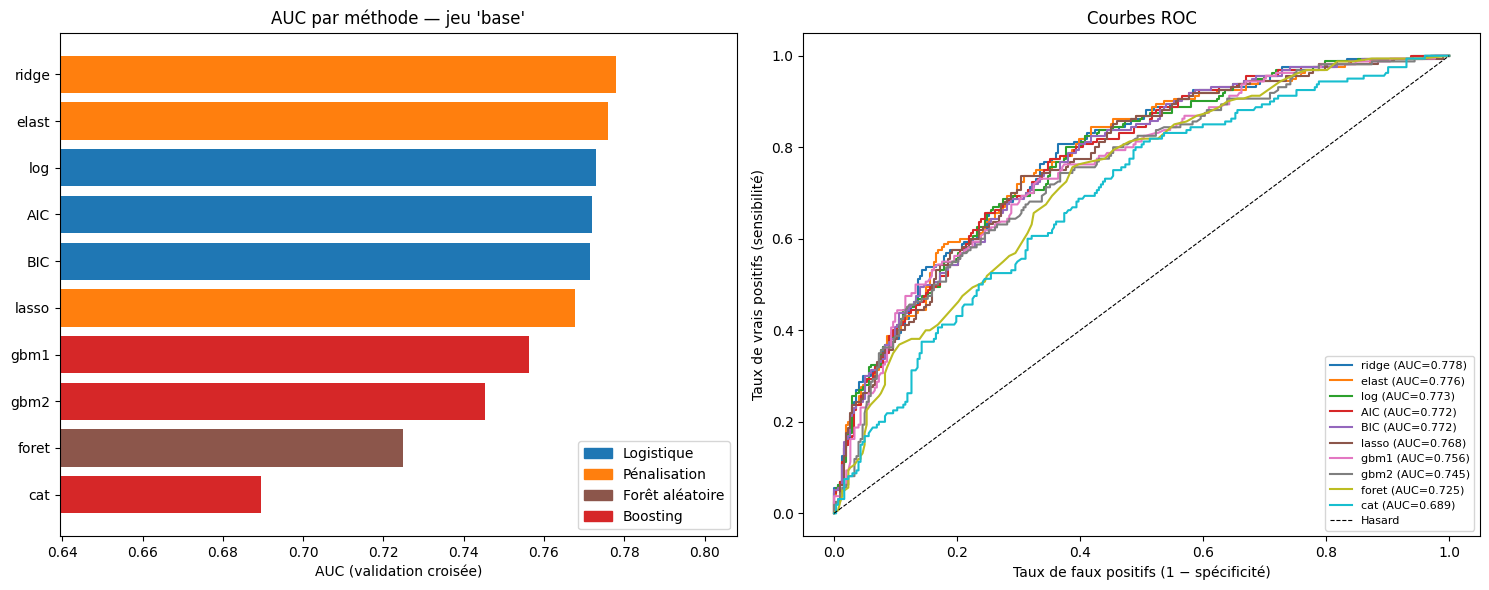

In [4]:
couleurs_famille = {"Logistique": "tab:blue", "Pénalisation": "tab:orange",
                    "Forêt aléatoire": "tab:brown", "Boosting": "tab:red"}
cmap = plt.get_cmap("tab10")

for jeu, (PROB, _, _) in resultats.items():
    t = tableaux[jeu]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    ax1.barh(t.index, t["AUC"], color=[couleurs_famille[f] for f in t["Famille"]])
    ax1.invert_yaxis()
    ax1.set_xlim(max(0.5, t["AUC"].min() - 0.05), min(1.0, t["AUC"].max() + 0.03))
    ax1.set_xlabel("AUC (validation croisée)")
    ax1.set_title(f"AUC par méthode — jeu '{jeu}'")
    ax1.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs_famille.values()], list(couleurs_famille),
               loc="lower right")

    for k, m in enumerate(t.index):
        fpr, tpr, _ = sklm.roc_curve(PROB.Y, PROB[m])
        ax2.plot(fpr, tpr, color=cmap(k % 10), linewidth=1.5, label=f"{m} (AUC={t.loc[m, 'AUC']:.3f})")
    ax2.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Hasard")
    ax2.set_xlabel("Taux de faux positifs (1 − spécificité)")
    ax2.set_ylabel("Taux de vrais positifs (sensibilité)")
    ax2.set_title("Courbes ROC")
    ax2.legend(loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.savefig(DOSSIER_SORTIE + f"resultats_CS_{jeu}.png", dpi=150)
    plt.show()

### 3.3 Hyperparamètres choisis par bloc
Variabilité des réglages d'un bloc à l'autre : C des méthodes pénalisées (grand C = peu de pénalisation), nombre de variables retenues (BIC/AIC) et nombre d'itérations retenues par l'early stopping (boosting). Un réglage très variable signale un modèle instable.

In [5]:
for jeu, (_, hyper, _) in resultats.items():
    hyper.index = [f"bloc {i}" for i in range(len(hyper))]
    resume = pd.DataFrame({"moyenne": hyper.mean(), "ecart_type": hyper.std(ddof=0)})
    resume["CV_%"] = 100 * resume["ecart_type"] / resume["moyenne"]
    print(f"\n--- Jeu '{jeu}' ---")
    display(hyper.round(3))
    display(resume.round(3))


--- Jeu 'base' ---


,nb_var_BIC,nb_var_AIC,C_ridge,C_lasso,C_elast,nb_iter_gbm1,nb_iter_gbm2,nb_iter_cat
bloc 0,5,6,0.038,0.134,0.074,63,24,3
bloc 1,5,7,0.038,0.091,0.072,92,48,7
bloc 2,5,5,0.069,0.127,0.339,33,25,5
bloc 3,3,5,0.048,0.050,0.340,92,28,10
bloc 4,5,5,0.063,0.320,0.232,84,48,5
bloc 5,5,5,0.044,0.042,0.028,41,35,3
bloc 6,5,5,0.027,0.060,0.048,89,51,0
bloc 7,5,6,0.045,0.302,0.114,190,44,3
bloc 8,5,5,0.044,0.067,0.044,92,87,1
bloc 9,5,6,0.028,0.052,0.031,38,12,1


,moyenne,ecart_type,CV_%
nb_var_BIC,4.800,0.600,12.500
nb_var_AIC,5.500,0.671,12.197
C_ridge,0.044,0.013,28.657
C_lasso,0.125,0.098,78.718
C_elast,0.132,0.118,89.226
nb_iter_gbm1,81.400,42.886,52.686
nb_iter_gbm2,40.200,19.768,49.173
nb_iter_cat,3.800,2.891,76.089


### 3.4 Évaluation sur l'échantillon de test final (si `TAILLE_TEST_FINAL > 0`)
Chaque modèle est réajusté sur **toutes** les observations de la validation croisée (hyperparamètres choisis par validation croisée interne, comme dans chaque bloc), puis évalué **une seule fois** sur le test final, resté à l'écart de toute sélection.
- **AUC_test** est l'estimation non biaisée de la performance du modèle retenu ; l'écart avec **AUC_cv** mesure l'optimisme dû au choix de la meilleure méthode sur les mêmes prédictions.
- Les intervalles de confiance (bootstrap) donnent l'ordre de grandeur de l'incertitude : l'échantillon de test est petit, des méthodes aux intervalles qui se recouvrent ne sont pas départageables.

In [6]:
def ic_auc(PROB, n_boot, graine):
    """Intervalle de confiance bootstrap à 95 % de l'AUC (mêmes rééchantillonnages pour toutes les méthodes)."""
    y = PROB["Y"].to_numpy()
    tirages = np.random.default_rng(graine).integers(0, len(y), size=(n_boot, len(y)))
    aucs = {m: [] for m in PROB.columns[1:]}
    for t in tirages:
        if len(np.unique(y[t])) < 2:
            continue
        for m in aucs:
            aucs[m].append(sklm.roc_auc_score(y[t], PROB[m].to_numpy()[t]))
    return pd.DataFrame({m: np.quantile(v, [0.025, 0.975]) for m, v in aucs.items()}, index=["bas", "haut"]).T


tableaux_test = {}
if not TESTS:
    print("Pas de test final (TAILLE_TEST_FINAL = 0).")
for jeu, tst in TESTS.items():
    P = tst["PROB"]
    ordre_cv = tableaux[jeu].index
    fixe, naturel = indicateurs(P, "fixe"), indicateurs(P, "naturel")
    ic = ic_auc(P, N_BOOT_IC, GRAINE)
    t = pd.DataFrame(index=ordre_cv)
    t["Famille"] = tableaux[jeu]["Famille"]
    t["Rang_cv"] = tableaux[jeu]["Rang_AUC"]
    t["AUC_cv"] = tableaux[jeu]["AUC"]
    t["AUC_test"] = [sklm.roc_auc_score(P.Y, P[m]) for m in ordre_cv]
    t["IC95_bas"], t["IC95_haut"] = ic["bas"], ic["haut"]
    t["Rang_test"] = t["AUC_test"].rank(ascending=False, method="min").astype(int)
    t["Accuracy_0.5"], t["F1_0.5"] = fixe["accuracy"], fixe["F1"]
    t["Accuracy_nat"], t["Medecin_nat"] = naturel["accuracy"], naturel["medecin"]
    tableaux_test[jeu] = t
    print(f"\n--- Jeu '{jeu}' : test final de {len(P)} observations (modèles ajustés sur {tst['n_cv']} observations) ---")
    display(t.round(3))
    display(pd.Series(tst["hyper"], name="réglage du modèle final").to_frame().round(4))

    pos = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(pos - 0.2, t["AUC_test"], height=0.4, color=[couleurs_famille[f] for f in t["Famille"]],
            xerr=[t["AUC_test"] - t["IC95_bas"], t["IC95_haut"] - t["AUC_test"]],
            error_kw=dict(ecolor="black", capsize=2, lw=1))
    ax.barh(pos + 0.2, t["AUC_cv"], height=0.4, color="lightgrey", edgecolor="grey")
    ax.set_yticks(pos)
    ax.set_yticklabels(t.index)
    ax.invert_yaxis()
    ax.set_xlim(0.4, 1.0)
    ax.set_xlabel("AUC")
    ax.set_title(f"Test final (± IC95, couleur) vs validation croisée (gris) — jeu '{jeu}'")
    plt.tight_layout()
    plt.savefig(DOSSIER_SORTIE + f"resultats_CS_test_final_{jeu}.png", dpi=150)
    plt.show()

Pas de test final (TAILLE_TEST_FINAL = 0).


## 4. Export des fichiers et synthèse
Les fichiers `PROB*.csv` sont lus par `03_analyseCS_complet.ipynb`.

In [7]:
for jeu, (PROB, hyper, _) in resultats.items():
    PROB.to_csv(DOSSIER_SORTIE + FICHIERS[jeu][1], index=False)
for jeu, tst in TESTS.items():
    tst["PROB"].to_csv(DOSSIER_SORTIE + FICHIERS[jeu][2], index=False)
if tableaux_test:
    pd.concat(tableaux_test, names=["features", "methode"]).round(4).to_csv(DOSSIER_SORTIE + "metriques_CS_test_final.csv")

pd.concat({jeu: t for jeu, t in tableaux.items()}, names=["features", "methode"]).round(4).to_csv(
    DOSSIER_SORTIE + "metriques_CS.csv")
pd.concat({jeu: r[1] for jeu, r in resultats.items()}, names=["features", "bloc"]).to_csv(
    DOSSIER_SORTIE + "hyperparametres_CS.csv")

for jeu, t in tableaux.items():
    meilleur = t.index[0]
    print(f"Jeu '{jeu}' : meilleure méthode (AUC) = {meilleur} (AUC = {t.loc[meilleur, 'AUC']:.3f}, "
          f"accuracy au seuil 0.5 = {t.loc[meilleur, 'Accuracy_0.5']:.3f}, médecin = {t.loc[meilleur, 'Medecin_nat']:.3f})")
    print("   Top 3 :", ", ".join(f"{m} ({t.loc[m, 'AUC']:.3f})" for m in t.index[:3]))

print("\nFichiers écrits :", ", ".join(FICHIERS[j][1] for j in JEUX),
      ", metriques_CS.csv, hyperparametres_CS.csv,", ", ".join(f"resultats_CS_{j}.png" for j in JEUX))
if TESTS:
    print("Test final :", ", ".join(FICHIERS[j][2] for j in TESTS), ", metriques_CS_test_final.csv,",
          ", ".join(f"resultats_CS_test_final_{j}.png" for j in TESTS))

Jeu 'base' : meilleure méthode (AUC) = ridge (AUC = 0.778, accuracy au seuil 0.5 = 0.732, médecin = 1.379)
   Top 3 : ridge (0.778), elast (0.776), log (0.773)

Fichiers écrits : PROB.csv , metriques_CS.csv, hyperparametres_CS.csv, resultats_CS_base.png
